# 09 — Image model for d1: preserved six-epoch B0 pilot

Four EfficientNet-B0 recipes were compared on one inner patient split, excluding
outer fold 0. This notebook reports saved best checkpoints. It **does not train,
tune thresholds or fit calibration**. AP remains the primary metric. The recipe
and epoch choices are exploratory, not a final outer evaluation.

The historical WIP experiment and all original pilot outputs remain preserved.
New figures and tables use `b0_pilot_reporting_v2`; architecture exploration is
separate in `10_image_architecture_comparison.ipynb`.


## Setup and historical verification

Verify archived source/configuration, preserved artifacts, development CSV,
fitting/validation image hashes, exact patient memberships and independently
recomputed metrics. Historical reporting uses recorded provenance, while
training resume retains its current-source compatibility guard. No reserved
 test files are accessed. Use the project `.venv`.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/melanoma_detection").is_dir() and (path / "configs/image_model.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.image_evaluation import load_historical_pilot, metric_table, curve_tables, sha256
from melanoma_detection.image_reporting import (plot_learning_curves, plot_training_losses,
    plot_roc_precision_recall, plot_confusion_matrices, plot_reliability_checks,
    plot_augmentation_preview, save_figure)
from melanoma_detection.metadata_evaluation import probability_metrics
pilot = load_historical_pilot(PROJECT_ROOT)
run_dir, report_dir = pilot["run_dir"], pilot["report_dir"]
figures_dir, tables_dir = report_dir / "figures", report_dir / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
config = pilot["manifest"]["compatibility"]["config"]
summary, history, predictions = pilot["summary"], pilot["histories"], pilot["predictions"]
epochs = dict(zip(pilot["records"].pipeline_id, pilot["records"].best_epoch))
plt.rcParams.update({"font.size": 10, "figure.facecolor": "white", "axes.facecolor": "white"})
print("Historical run:", summary["status"], "| saved compatibility:", pilot["manifest"]["compatibility_sha256"])
display(pd.DataFrame([pilot["verification"]]))
display(pd.DataFrame([pilot["manifest"]["compatibility"]["runtime"]["packages"]]))


Historical run: complete | saved compatibility: e8b08f551f3785c74ace53f5b5dc5d282f146de04bdbd7a1df82a48277ed4fbc


,archive_verified,artifacts_verified,checkpoints_verified,images_verified,reserved_test_loaded
0,True,True,True,True,False


,torch,torchvision,numpy,pandas,scikit-learn,Pillow,PyYAML
0,2.14.0+cu130,0.29.0+cu130,2.5.2,3.0.5,1.9.0,12.3.0,6.0.3


## Patients and preparation

Patient groups stay together. Only RGB images enter the model; outer-excluded
class labels do not enter this report. Whole-image 224×224 bilinear resizing,
weak flips/±20° rotation, unchanged preprocessing and ImageNet normalisation
remain the reference. Validation preparation is deterministic.


In [2]:
partitions = {"fitting": pilot["fitting"], "inner_validation": pilot["validation"],
    "outer_excluded": pilot["outer_excluded"]}
display(pd.DataFrame([{"partition": name, "images": len(frame),
    "patients": frame.patient_id.nunique(), "melanoma_images":
    int(frame.target.sum()) if name != "outer_excluded" else np.nan}
    for name, frame in partitions.items()]).style.format(na_rep="Not used"))
audit = pilot["image_audit"]
print("Audited images:", audit["images"], "| within-patient duplicate groups:",
    len(audit["duplicate_groups_within_patient"]), "| label conflicts:", audit["label_conflicts"])
print("Patient overlap: 0 | outer predictions: none | reserved test loaded: False")
display(pd.DataFrame(config["candidates"]["pilot_recipes"]))
display(pd.DataFrame([config["training"]]))


,partition,images,patients,melanoma_images
0,fitting,3660,225,70.000000
1,inner_validation,1834,113,33.000000
2,outer_excluded,1370,84,Not used


Audited images: 6864 | within-patient duplicate groups: 158 | label conflicts: 0
Patient overlap: 0 | outer predictions: none | reserved test loaded: False


,id,backbone_lr,loss_weight
0,lr3e5_none,0.00003,none
1,lr1e4_none,0.00010,none
2,lr3e5_sqrt,0.00003,sqrt_ratio
3,lr1e4_sqrt,0.00010,sqrt_ratio


,microbatch,effective_batch,min_microbatch,head_lr,weight_decay,warmup_epochs,schedule_epochs,min_lr_factor,gradient_clip,amp,num_workers,seed
0,64,64,4,0.001,0.0001,1,30,0.1,1.0,True,0,42


The fitting-only preview deliberately mixes labels. Existing rotation creates
black corners and can remove peripheral pixels. Sampled central texture and
pigmentation remain visible; this small check does not certify every lesion.
Stronger augmentation and its broader quality review remain deferred.


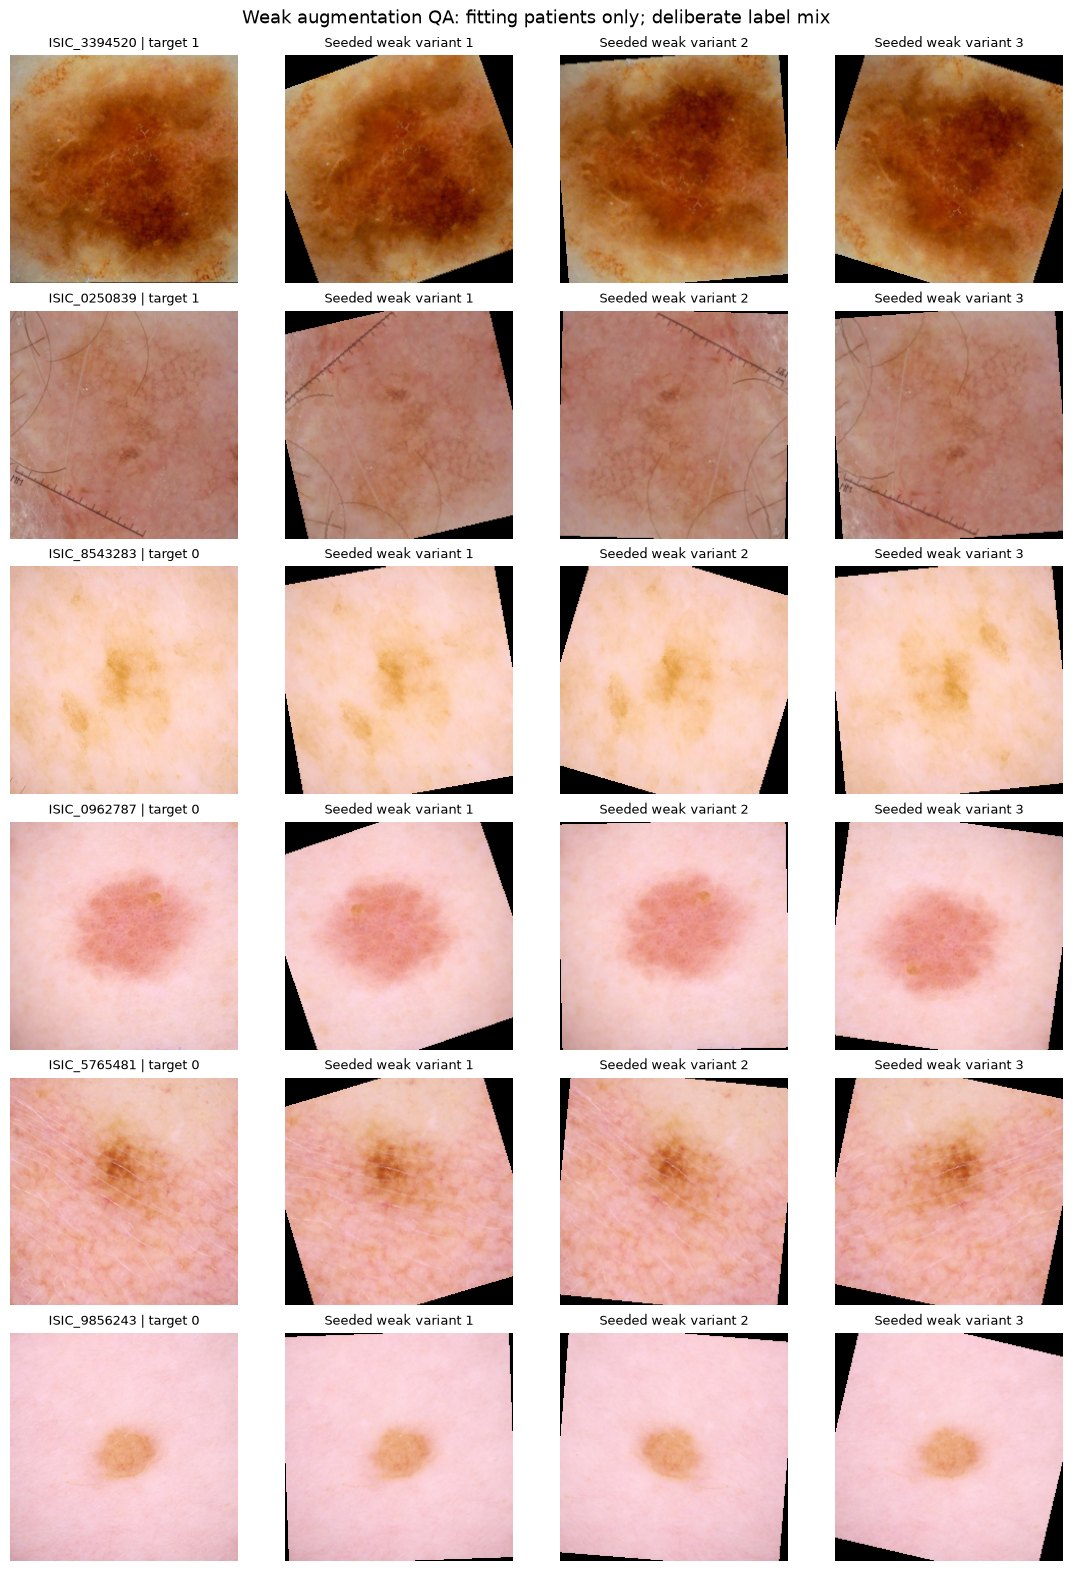

In [3]:
preview = plot_augmentation_preview(pilot["fitting"], config["model"])
save_figure(preview, figures_dir / "weak_augmentation_preview.png", dpi=130)
plt.show()


## Exploratory probability and resource metrics

Select each recipe's actual highest inner-validation AP checkpoint; exact ties
retain the earlier epoch. All trials completed six epochs under the fixed
30-epoch scheduler, including one classifier-only warmup. The maximum training
budget differs from the selected epoch. Weighting uses fitting patients only.


In [4]:
metrics = metric_table(predictions, threshold=.5, epochs=epochs)
metrics.to_csv(tables_dir / "exploratory_metrics_threshold_0_5.csv", index=False)
probability_columns = ["pipeline_id", "selected_epoch", "average_precision", "roc_auc", "log_loss", "brier"]
display(metrics[probability_columns].style.format({key: "{:.4f}" for key in probability_columns[2:]}))
baseline = probability_metrics(pilot["validation"].target,
    np.full(len(pilot["validation"]), pilot["fitting"].target.mean()))
display(pd.DataFrame([{"reference": "Constant fitting-prevalence score", **baseline}]))
resources = history.groupby("pipeline_id").agg(completed_epochs=("epoch", "max"),
    measured_training_minutes=("epoch_seconds", lambda values: values.sum() / 60),
    mean_epoch_seconds=("epoch_seconds", "mean"),
    peak_allocated_GiB=("peak_memory_bytes", lambda values: values.max() / 2**30),
    microbatch=("microbatch", "min"), skipped_AMP_updates=("skipped_optimizer_updates", "sum"))
resources.to_csv(tables_dir / "measured_resources.csv")
display(resources.style.format({"measured_training_minutes": "{:.2f}",
    "mean_epoch_seconds": "{:.2f}", "peak_allocated_GiB": "{:.2f}"}))


,pipeline_id,selected_epoch,average_precision,roc_auc,log_loss,brier
0,efficientnet_b0/lr3e5_none,5,0.1155,0.8426,0.0774,0.0170
1,efficientnet_b0/lr1e4_none,4,0.1119,0.8602,0.0763,0.0169
2,efficientnet_b0/lr3e5_sqrt,6,0.1383,0.8663,0.0876,0.0210
3,efficientnet_b0/lr1e4_sqrt,6,0.1097,0.8734,0.0793,0.0199


,reference,average_precision,roc_auc,log_loss,brier
0,Constant fitting-prevalence score,0.017993,0.5,0.090159,0.017671


,completed_epochs,measured_training_minutes,mean_epoch_seconds,peak_allocated_GiB,microbatch,skipped_AMP_updates
pipeline_id,,,,,,
efficientnet_b0/lr1e4_none,6,3.29,32.85,2.81,64,7
efficientnet_b0/lr1e4_sqrt,6,3.47,34.69,2.81,64,8
efficientnet_b0/lr3e5_none,6,3.43,34.30,2.81,64,7
efficientnet_b0/lr3e5_sqrt,6,3.31,33.06,2.81,64,8


## Learning trajectories and selected epochs

Hollow rings mark highest-AP epochs. The dotted vertical line separates warmup
from fine-tuning. Validation log loss is unweighted for every recipe. Weighted
and unweighted fitting losses use different objectives: their magnitudes are
shown separately and must not rank weighted against unweighted models.


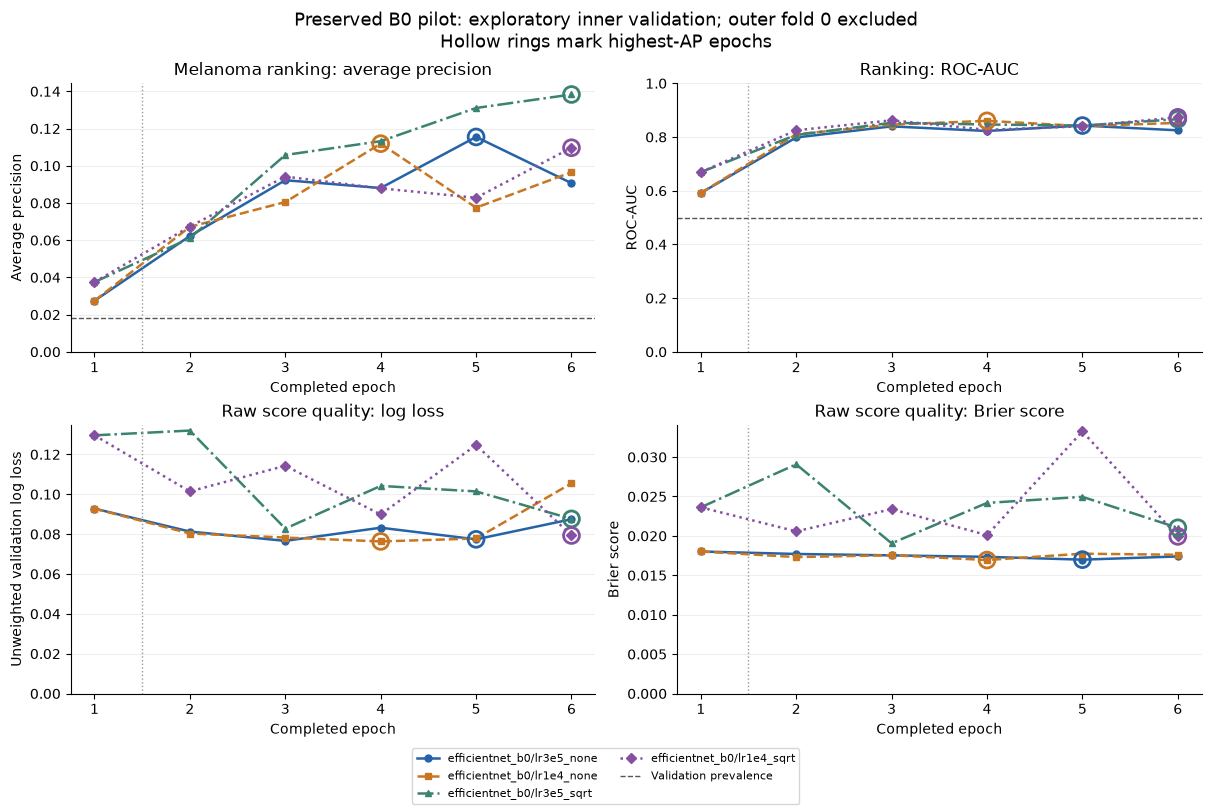

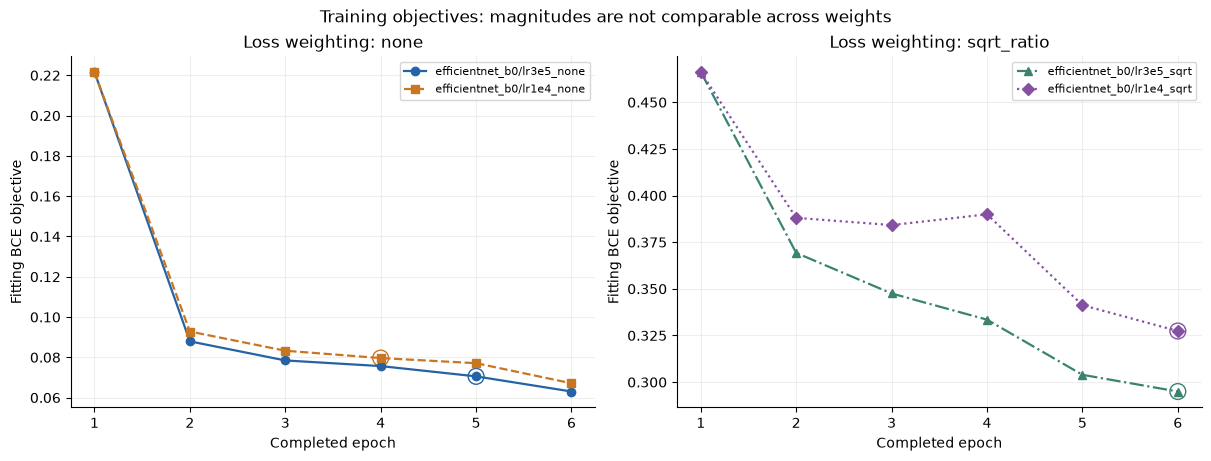

In [5]:
learning = plot_learning_curves(history, pilot["validation"].target.mean(),
    "Preserved B0 pilot: exploratory inner validation; outer fold 0 excluded")
save_figure(learning, figures_dir / "learning_curves.png")
plt.show()
losses = plot_training_losses(history)
save_figure(losses, figures_dir / "training_loss_by_weight.png")
plt.show()


## Actual ROC and precision–recall curves

Curves use saved best-checkpoint scores on the same 1,834 images from 113
patients. AP is average precision, not trapezoidal precision–recall area.
Checkpoint and recipe selection reuse these patients; reports are exploratory.


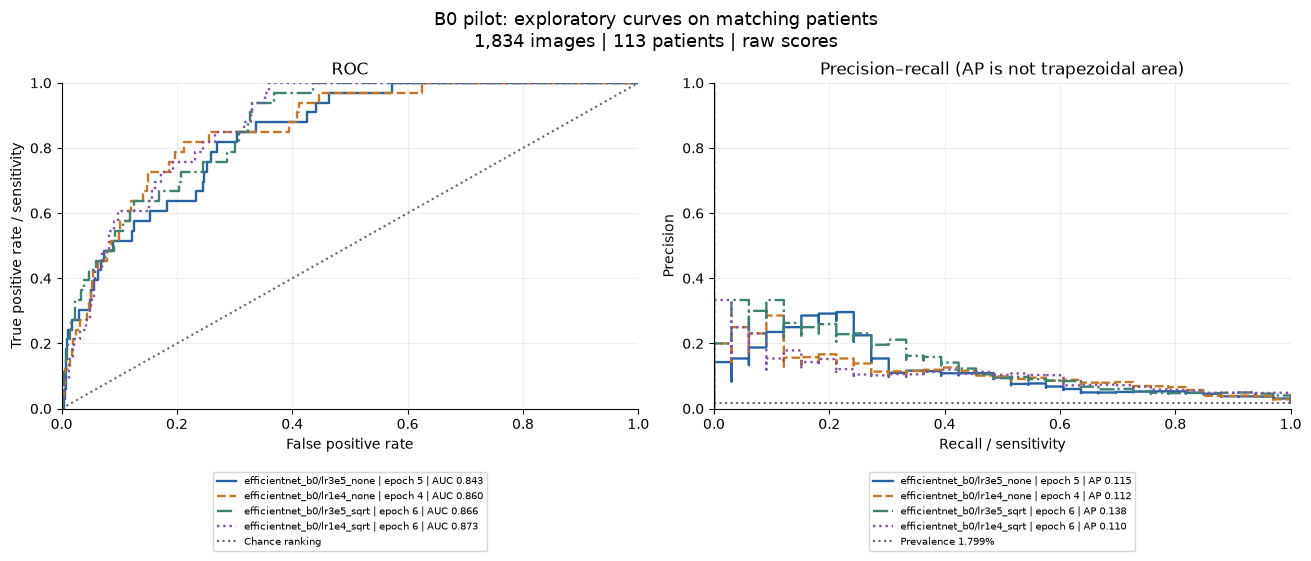

In [6]:
curves = plot_roc_precision_recall(predictions, epochs=epochs,
    title="B0 pilot: exploratory curves on matching patients")
save_figure(curves, figures_dir / "roc_precision_recall.png")
plt.show()
for identity, frame in predictions.items():
    for name, table in curve_tables(frame.target, frame.base_probability).items():
        if isinstance(table, pd.DataFrame):
            table.to_csv(tables_dir / f"{identity.replace('/', '__')}_{name}.csv", index=False)


## Classification at the fixed raw threshold 0.5

Flag an image when `base_probability >= 0.5`. This threshold is fixed, not tuned
on validation labels. Report sensitivity/recall, specificity, precision, F1 and
all confusion counts. Undefined denominators remain missing. F1 is
`2TP / (2TP + FP + FN)` when the denominator is nonzero.

The academic 80%-recall scenario is deferred until training-only OOF scores
exist. Outer evaluation labels will never choose a threshold.


,pipeline_id,selected_epoch,threshold,score_type,TP,FP,TN,FN,precision,recall,sensitivity,specificity,f1,n_images,n_patients
0,efficientnet_b0/lr3e5_none,5,0.500000,raw_base_probability,0,1,1800,33,0.0000,0.0000,0.0000,0.9994,0.0000,1834,113
1,efficientnet_b0/lr1e4_none,4,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000,1834,113
2,efficientnet_b0/lr3e5_sqrt,6,0.500000,raw_base_probability,4,14,1787,29,0.2222,0.1212,0.1212,0.9922,0.1569,1834,113
3,efficientnet_b0/lr1e4_sqrt,6,0.500000,raw_base_probability,3,14,1787,30,0.1765,0.0909,0.0909,0.9922,0.1200,1834,113


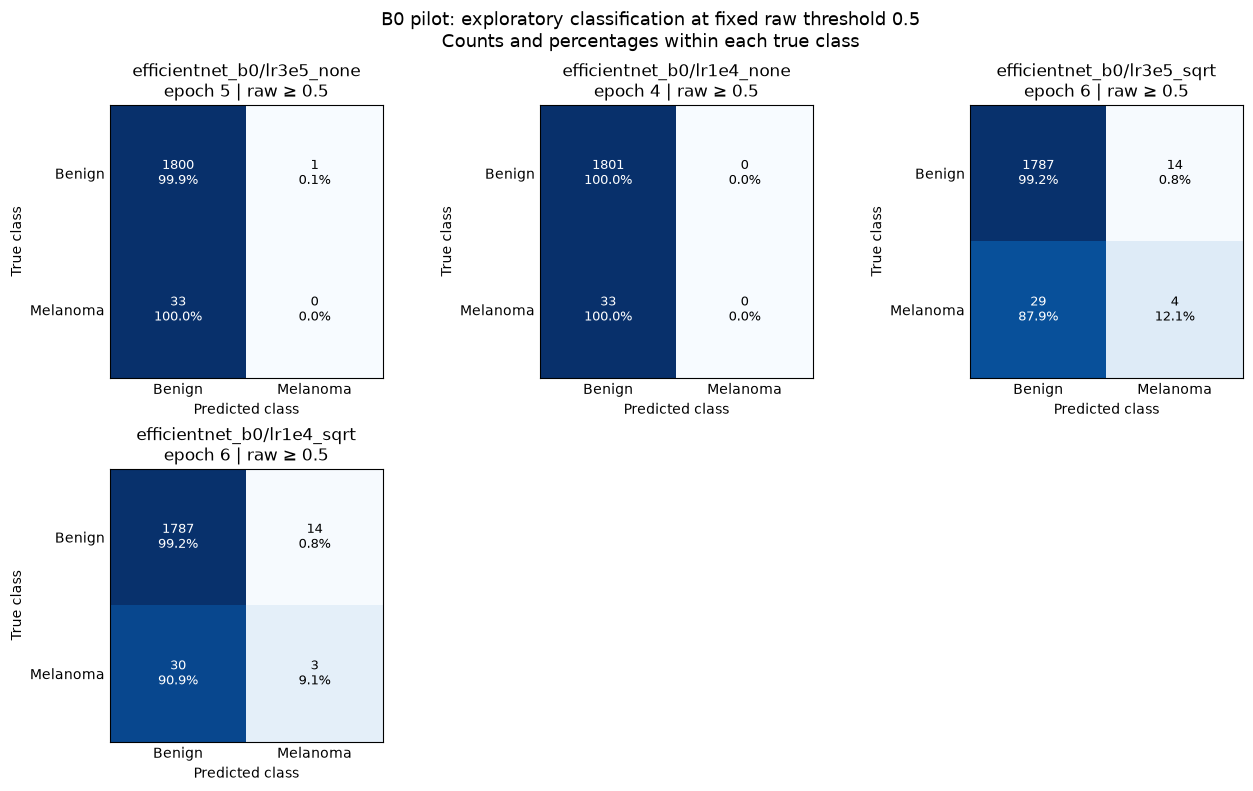

At threshold 0.5 the preferred weighted recipe detects 4 of 33 melanoma images (recall 12.1%) and flags 14 benign images. Ranking performance alone does not establish useful classification at this cutoff.

In [7]:
classification_columns = ["pipeline_id", "selected_epoch", "threshold", "score_type", "TP", "FP", "TN", "FN",
    "precision", "recall", "sensitivity", "specificity", "f1", "n_images", "n_patients"]
display(metrics[classification_columns].style.format({name: "{:.4f}" for name in
    ["precision", "recall", "sensitivity", "specificity", "f1"]}, na_rep="Undefined"))
confusion = plot_confusion_matrices(predictions, epochs=epochs, threshold=.5,
    title="B0 pilot: exploratory classification at fixed raw threshold 0.5")
save_figure(confusion, figures_dir / "confusion_threshold_0_5.png")
plt.show()
display(Markdown("At threshold 0.5 the preferred weighted recipe detects 4 of 33 melanoma images "
    "(recall 12.1%) and flags 14 benign images. Ranking performance alone does not establish "
    "useful classification at this cutoff."))


## Raw-score calibration checks

Equal-count bins describe mean raw score against observed melanoma fraction;
support counts are saved. Bins may share patients and contain few positives.
These are raw-score checks, not calibration fitting or verified clinical risk.


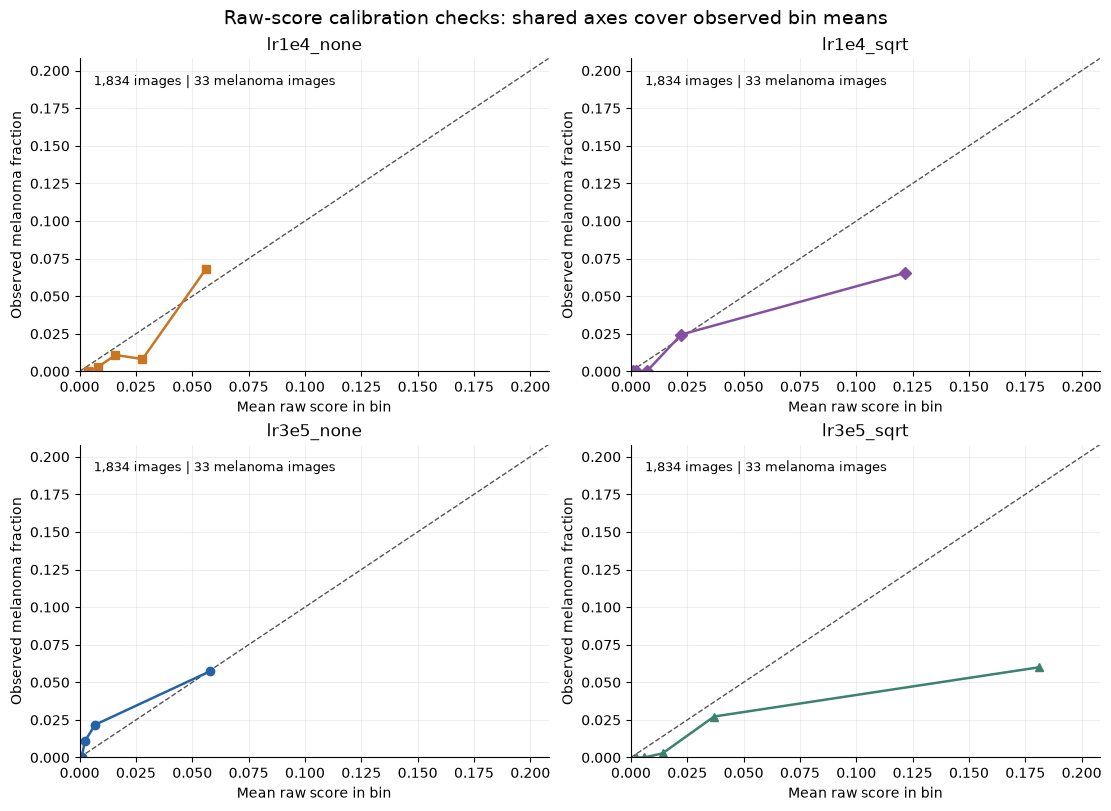

,recipe_id,bin,n_images,n_malignant_images,n_patients,mean_probability,observed_rate
0,lr1e4_none,1,367,0,37,0.0039,0.0000
1,lr1e4_none,2,367,1,68,0.0080,0.0027
2,lr1e4_none,3,366,4,78,0.0159,0.0109
3,lr1e4_none,4,367,3,87,0.0279,0.0082
4,lr1e4_none,5,367,25,77,0.0561,0.0681
5,lr1e4_sqrt,1,367,0,36,0.0009,0.0000
6,lr1e4_sqrt,2,367,0,53,0.0021,0.0000
7,lr1e4_sqrt,3,366,0,82,0.0070,0.0000
8,lr1e4_sqrt,4,367,9,86,0.0224,0.0245
9,lr1e4_sqrt,5,367,24,81,0.1214,0.0654


In [8]:
reliability = plot_reliability_checks(run_dir)
save_figure(reliability, figures_dir / "raw_reliability.png")
plt.show()
bins = pd.concat([pd.read_csv(path).assign(recipe_id=path.parent.name)
    for path in sorted((run_dir / "recipes").glob("*/reliability.csv"))], ignore_index=True)
bins.to_csv(tables_dir / "raw_reliability_support.csv", index=False)
display(bins[["recipe_id", "bin", "n_images", "n_malignant_images", "n_patients",
    "mean_probability", "observed_rate"]].style.format(
    {"mean_probability": "{:.4f}", "observed_rate": "{:.4f}"}))


## Interpretation and next stage

The preferred B0 recipe has AP 0.1383 at epoch 6. Its late peak motivates longer
validation, but this three-hour session prioritises architecture feasibility.
B0 is the reference, not the predetermined winner. DenseNet121 and ConvNeXt-Tiny
have their own learning-rate candidates and epoch choices.

Longer three-fold validation, stronger augmentation, hair/lighting, Swin,
calibration and final nested evaluation are deferred. Short trials cannot
remove slower families or transformations globally. Uncertainty and fusion
retain separate historical inputs; the reserved test stays outside development.


In [9]:
display(Markdown(summary["recommendation"]))
display(pd.DataFrame([summary["runtime_estimates"]]))
(report_dir / "reporting_receipt.json").write_text(json.dumps({
    "reporting_version": 2, "historical_run_id": "b0_pilot_v1", "verified": pilot["verification"],
    "threshold": .5, "threshold_tuned": False, "calibration_fitted": False,
    "outer_predictions_generated": False,
    "status": summary["status"],
    "reporting_source_sha256": {relative: sha256(PROJECT_ROOT / relative) for relative in [
        "src/melanoma_detection/image_evaluation.py", "src/melanoma_detection/image_reporting.py",
        "scripts/build_image_notebook.py"]},
    "summary_sha256": sha256(run_dir / "summary.json"),
    "prediction_csv_sha256": {str(path.relative_to(PROJECT_ROOT)): sha256(path)
        for path in sorted((run_dir / "recipes").glob("*/inner_validation_predictions.csv"))},
    "figures": sorted(path.name for path in figures_dir.glob("*.png"))}, indent=2), encoding="utf-8")
print("New reports:", report_dir)
print("Original pilot artifacts: unchanged | outer evaluation: not performed | calibration: not fitted")


Best inner AP is near the pilot cap; extend all four candidates on inner patients to a 30-epoch cap before stronger claims.

,measured_b0_mean_epoch_seconds,four_30_epoch_b0_fit_hours_same_split,future_nested_maximum_logical_fits,future_nested_maximum_unequal_training_epochs,optional_swin_added_fits,optional_stability_added_fits,future_hours,qualification
0,33.726012,1.1242,180,4380,35,10,None,B0 pilot timing cannot estimate unequal unmeas...


New reports: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\image_d1_runs\b0_pilot_reporting_v2
Original pilot artifacts: unchanged | outer evaluation: not performed | calibration: not fitted


## Limitations

- One inner patient split and six training epochs provide early learning evidence.
- Recipe and checkpoint selection reuse inner validation labels; results are not unbiased outer evaluation.
- Raw threshold 0.5 is fixed and can have low melanoma recall. Tuned thresholds and calibration require training-only OOF scores.
- Raw weighted/unweighted scores use different scales, and their fitting-loss magnitudes are not comparable.
- Other architectures, transformations and final nested evaluation have separate stages; uncertainty, fusion and reserved-test evaluation remain separate.


## Summary

The preserved pilot is the B0 reference. Its measured recommendation below is
exploratory and does not determine another architecture's recipe or final model.


In [10]:
preferred = summary.get("selected_recipe")
if preferred is not None:
    selected = pilot["records"].loc[pilot["records"].recipe_id.eq(preferred)]
    display(selected[["pipeline_id", "best_epoch", "average_precision", "roc_auc", "log_loss", "brier"]])
display(Markdown(summary["recommendation"]))
print("Completed four six-epoch trials; no final architecture chosen and no outer/test evaluation performed.")


,pipeline_id,best_epoch,average_precision,roc_auc,log_loss,brier
2,efficientnet_b0/lr3e5_sqrt,6,0.138318,0.866337,0.087642,0.021026


Best inner AP is near the pilot cap; extend all four candidates on inner patients to a 30-epoch cap before stronger claims.

Completed four six-epoch trials; no final architecture chosen and no outer/test evaluation performed.
